<a href="https://colab.research.google.com/github/PabloShol/simulacion2/blob/main/M%C3%A9todo_de_Euler_Maruyama.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# parametros
r = 0.1
sigma = 0.3
y0 = 1.0
dt = 0.2
T = 8.0
N = int(T / dt)
M = 1000

#semilla
np.random.seed(42)

In [ ]:
def f(t, w):
  return r * w

def g(t, w):
  return sigma * w

t = np.linspace(0, T, N + 1)
w = np.zeros((M, N + 1))
y = np.zeros((M, N + 1))

w[:, 0] = y0
y[:, 0] = y0

for m in range(M):
  B_t = 0.0
  for i in range(N):
    Z_i = np.random.normal(0,1)
    dB_i = Z_i * np.sqrt(dt)

    w[m, i + 1] = w[m, i] + f(t[i], w[m, i]) * dt + g(t[i], w[m, i]) * dB_i
    B_t += dB_i
    y[m, i + 1] = y0 * np.exp((r-0.5*sigma**2)*t[i+1]+sigma*B_t)

In [ ]:
error_medio = np.mean(y[:, -1] - w[:, -1])
error_absoluto_medio = np.mean(np.abs(y[:, -1] - w[:, -1]))

In [ ]:
print(f"Numero de realizaciones: {M}")
print(f"Numero de pasos: {N} con dt = {dt}")
print(f"Valor esperado teorico E[y(T)] = y0 * exp(r*T): {y0 * np.exp(r * T):.6f}")
print(f"Promedio simulado solución exacta E[y(T)]: {np.mean(y[:, -1]):.6f}")
print(f"Promedio simulado Euler - Maruyama E[y(T)]: {np.mean(w[:, -1]):.6f}")
print("-" * 55)
print(f"Error E{{y(T) - w(T)}}: {error_medio:.6f}")
print(f"Error E{{/y(T) - w(T)/}}: {error_absoluto_medio:.6f}")

Numero de realizaciones: 1000
Numero de pasos: 40 con dt = 0.2
Valor esperado teorico E[y(T)] = y0 * exp(r*T): 2.225541
Promedio simulado solución exacta E[y(T)]: 2.198712
Promedio simulado Euler - Maruyama E[y(T)]: 2.187685
-------------------------------------------------------
Error E{y(T) - w(T)}: 0.011027
Error E{/y(T) - w(T)/}: 0.134163


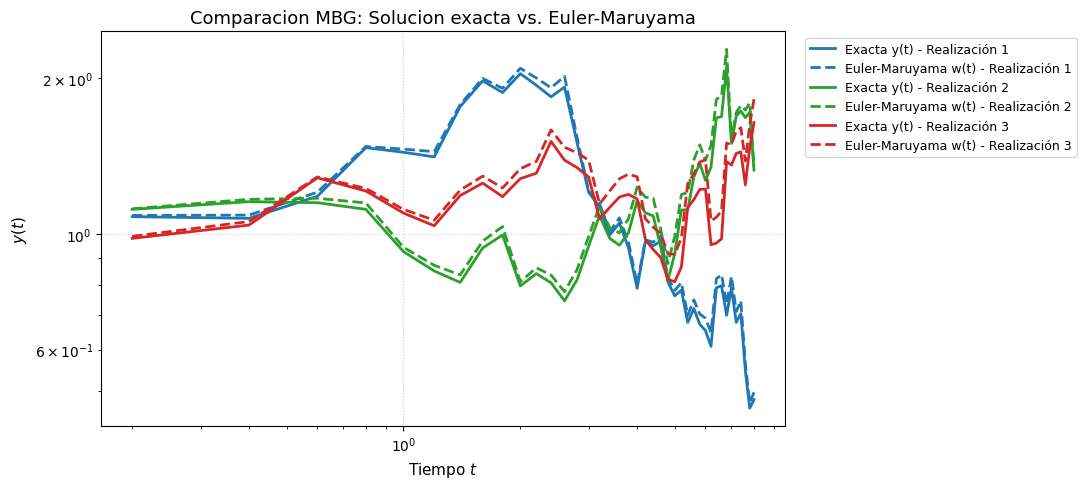

In [ ]:
plt.figure(figsize=(11, 5))
colores = ['#1f77b4', '#2ca02c', '#d62728']
for k in range(3):
  plt.loglog(t[1:], y[k, 1:], color=colores[k], linestyle='-', linewidth=2,
           label=f'Exacta y(t) - Realización {k+1}')
  plt.loglog(t[1:], w[k, 1:], color=colores[k], linestyle='--', linewidth=2,
           label=f'Euler-Maruyama w(t) - Realización {k+1}')

plt.title('Comparacion MBG: Solucion exacta vs. Euler-Maruyama', fontsize=13)
plt.xlabel('Tiempo $t$', fontsize = 11)
plt.ylabel('$y(t)$', fontsize=11)
plt.grid(True, linestyle = ':', alpha = 0.6)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=9)
plt.tight_layout()
plt.show()